# Compact block round trips: daily charts

Why compact blocks needed a round trip (a `getblocktxn` for txs our mempool lacked), on sampled days before,
during and after the fleet. Draws five views from a node's debug.logs and its blocks:

1. **Day by day**: round trips per day, and how many would not have happened without P2A chains
2. **Missing transactions by cause**
3. **First missing tx of each P2A chain**: what our mempool had instead
4. **Block transactions by kind**
5. **Time to rebuild each block**

The scripts in `scripts/roundtrip/` turn the logs and the node's blocks into the CSVs in `data/roundtrip/` (the
README lists what the node needs); this notebook only reads them. The files in the repo come from our node, on
26 days: Jun 6, 7, 12 and 13 before the fleet; Jul 12, 13, 16, 17, 23, 24, 26, 27, Aug 8, 9, 12, 13, Sep 5, 6,
Oct 5, 6, 11 and 12 while it was active; and Oct 20, 21, 26 and 27 after it.

- `data/roundtrip/blocks.csv`: one row per compact block reconstructed, with its rebuild time, what the log says
  it requested, how many txs it was missing by our count and those split by cause.
- `data/roundtrip/causes.csv`: missing txs per day and cause.
- `data/roundtrip/chain_heads.csv`: the first missing tx of each P2A chain, by what our mempool held instead.
- `data/roundtrip/block_types.csv`: the day's block txs by kind.

Causes of a missing tx (a P2A chain tx takes the cause of the first missing tx above it in its chain, since a
child cannot enter the mempool without its parent):

| cause | rule |
|---|---|
| sweeper kept, chain mined | the chain's first missing tx was refused for its fee, which was exactly its parent's anchor value: our mempool held a sweeper of that anchor |
| chain kept, sweeper mined | the first missing tx is a sweeper, refused for its fee |
| root refused | the first missing tx creates the chain's first anchor and was refused for its fee: another tx spent one of its inputs |
| other P2A | any other P2A chain tx |
| 140 vB rune mints | 139-141 vB, 1 input, 2 outputs, a runestone, no P2A |
| everything else | the rest |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path('data/roundtrip')
# the fleet as the discussion defines it: /txbroadcast:0.1/ first seen to /Satoshi:31.0.0/ (70015) last seen
FLEET_FIRST_DAY, FLEET_LAST_DAY = '2026-07-04', '2026-10-18'

## 1. Load

In [2]:
blocks = pd.read_csv(DATA / 'blocks.csv')
causes = pd.read_csv(DATA / 'causes.csv')
heads = pd.read_csv(DATA / 'chain_heads.csv')
kinds = pd.read_csv(DATA / 'block_types.csv')


def period(day):
    return 'before' if day < FLEET_FIRST_DAY else 'after' if day > FLEET_LAST_DAY else 'during'


PERIOD_NAMES = {'before': 'Before the fleet', 'during': 'Fleet active', 'after': 'After the fleet'}
CAUSES = ['p2a_sweeper_won_here', 'p2a_chain_won_here', 'p2a_root_conflict', 'p2a_other', 'rune140', 'other']
P2A_CAUSES = CAUSES[:4]
days = sorted(blocks.day.unique())
print(f'{len(blocks)} blocks on {len(days)} days: ' + ', '.join(pd.to_datetime(days).strftime('%b %-d')))

3771 blocks on 26 days: Jun 6, Jun 7, Jun 12, Jun 13, Jul 12, Jul 13, Jul 16, Jul 17, Jul 23, Jul 24, Jul 26, Jul 27, Aug 8, Aug 9, Aug 12, Aug 13, Sep 5, Sep 6, Oct 5, Oct 6, Oct 11, Oct 12, Oct 20, Oct 21, Oct 26, Oct 27


## 2. Chart style

The same palette as `p2a_fleet_charts.ipynb`, in its fixed order; "everything else" is neutral gray. Each day is
one 100% bar, its total on the right.

In [3]:
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#8a8a85'
INK, MUTED, GRID, AXIS, SURFACE = '#1f1e1d', '#6b6a64', '#e6e5e0', '#a9a8a2', '#ffffff'

plt.rcParams.update({
    'font.size': 9, 'axes.titlesize': 9, 'axes.titlelocation': 'left', 'axes.titlecolor': INK,
    'axes.edgecolor': AXIS, 'axes.labelcolor': MUTED, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.spines.left': False,
    'ytick.left': False, 'figure.dpi': 110,
})


def compact(v):
    for div, suffix in ((1e9, 'B'), (1e6, 'M'), (1e3, 'K')):
        if abs(v) >= div:
            return f'{v / div:.1f}'.rstrip('0').rstrip('.') + suffix
    return f'{v:,.0f}'


def day_rows(days):
    """y of each day, top to bottom, with a gap and a caption above each period"""
    y, rows, captions, prev = 0, {}, [], None
    for day in days:
        if period(day) != prev:
            prev = period(day)
            captions.append((y, PERIOD_NAMES[prev]))
            y += 0.9
        rows[day] = y
        y += 1
    return rows, captions, y


def day_axis(ax, days):
    rows, captions, bottom = day_rows(days)
    ax.set_ylim(bottom - 0.3, -0.3)
    ax.set_yticks([rows[d] for d in days], pd.to_datetime(days).strftime('%b %-d'), color=INK)
    for y, name in captions:
        ax.text(0, y + 0.25, name, transform=ax.get_yaxis_transform(), color=MUTED, fontweight='bold', va='center')
    return rows


def stack_rows(counts, series, title, total_fmt=lambda v: f'{v:,.0f}', empty=''):
    """one 100% bar per day; counts: days x series keys; series: [(key, label, color)]; empty: text for a day
    with no counts"""
    days = list(counts.index)
    height = 0.42 * len(days) + 1.6
    fig, ax = plt.subplots(figsize=(11, height))
    # the space under the title in inches: as a fraction of the figure it would grow with the number of days
    fig.subplots_adjust(top=1 - 0.35 / height)
    rows = day_axis(ax, days)
    totals = counts.sum(axis=1)
    for day in days:
        if not totals[day]:
            ax.text(0.005, rows[day], empty, va='center', fontsize=8, color=MUTED)
        left = 0
        for key, label, color in series:
            share = counts.at[day, key] / totals[day] if totals[day] else 0
            if share:
                # the white edge leaves a gap between segments
                ax.barh(rows[day], share, left=left, height=0.7, color=color, edgecolor=SURFACE, lw=1.5)
                if share > 0.06:
                    ax.text(left + 0.008, rows[day], f'{share:.0%}', va='center', fontsize=8,
                            color=INK if color in (AQUA, YELLOW, MAGENTA, GRAY) else 'white')
            left += share
        ax.text(1.01, rows[day], total_fmt(totals[day]), va='center', color=MUTED)
    ax.set_xlim(0, 1)
    ax.xaxis.set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for _, _, c in series], labels=[l for _, l, _ in series],
              loc='upper left', bbox_to_anchor=(0, 0), ncol=3, frameon=False, fontsize=8)
    fig.suptitle(title, x=0.125, y=1.0, ha='left', fontsize=12, color=INK)
    plt.show()

## 3. Day by day

A block "needed a round trip" when it requested at least one tx. "Spared without P2A" counts round-trip blocks
whose missing txs were all P2A chain txs, all of them blamed on the fleet and `/p2aburn:1.0/` since the log does
not say who sent each chain. "Spared, estimated" also counts round-trip blocks that still miss other txs, weighted
by how often a block missing that many went without a round trip on the days outside the fleet window, when the
extra pool filled such gaps. It is an estimate: those days' P2A chains are in that rate, and the fleet also filled
the orphanage, so some of the other missing txs may be its doing too.

"Matches the log": the rebuilt missing count lands between the logged "txn requested" and "requested + extra
pool", or within 10% of "requested" (at least 2). Each day uses the three days before it as mempool history.

In [4]:
MISSING_BUCKETS = [0, 5, 20, 50, 100, 300]


def bucket(n):
    """index of the first bucket bound n fits under; -1 above the last"""
    return next((i for i, bound in enumerate(MISSING_BUCKETS) if n <= bound), -1)


def matches_log(b):
    return (b.requested <= b.calc_missing <= b.requested + b.extra_pool
            or abs(b.calc_missing - b.requested) <= max(2, 0.1 * b.requested))


b = blocks.assign(
    period=blocks.day.map(period),
    round_trip=blocks.requested > 0,
    p2a=blocks[P2A_CAUSES].sum(axis=1),
    rest=blocks.rune140 + blocks.other,
    matches=blocks.apply(matches_log, axis=1),
)
# how often a block missing that many txs went without a round trip, outside the fleet window
no_round_trip_rate = (b[b.period != 'during'].assign(bucket=lambda d: d.calc_missing.map(bucket))
                      .groupby('bucket').round_trip.apply(lambda s: 1 - s.mean()))
hit = b[b.round_trip & (b.p2a > 0)]
spared_exact = hit[hit.rest == 0].groupby('day').size()
spared_est = hit.assign(rate=hit.rest.map(bucket).map(no_round_trip_rate).fillna(0)).groupby('day').rate.sum()

per_day = b.groupby('day').agg(
    blocks=('height', 'size'), round_trips=('round_trip', 'sum'), requested=('requested', 'sum'),
    requested_bytes=('requested_bytes', 'sum'), median_ms=('reconstruct_ms', 'median'), matches=('matches', 'sum'))
table = pd.DataFrame({
    'Blocks': per_day.blocks.map('{:,}'.format),
    'Needed a round trip': (per_day.round_trips / per_day.blocks).map('{:.0%}'.format),
    'Spared without P2A': spared_exact.reindex(per_day.index, fill_value=0).map('{:,}'.format),
    'Spared, estimated': spared_est.reindex(per_day.index, fill_value=0).map(lambda v: f'~{v:,.0f}'),
    'Txs requested': per_day.requested.map('{:,}'.format),
    'Bytes requested': per_day.requested_bytes.map(lambda v: f'{v / 1e6:.1f} MB' if v >= 1e6 else f'{v / 1e3:.0f} kB'),
    'Median rebuild': per_day.median_ms.map(lambda v: '-' if pd.isna(v) else f'{v:,.0f} ms'),
    'Matches the log': per_day.matches.astype(str) + ' of ' + per_day.blocks.astype(str),
}).T
table.columns = pd.MultiIndex.from_tuples([(PERIOD_NAMES[period(d)], pd.Timestamp(d).strftime('%b %-d'))
                                          for d in table.columns])
low = (per_day.matches / per_day.blocks).idxmin()
print(f'{per_day.matches.sum():,} of {per_day.blocks.sum():,} blocks match the log; '
      f'lowest: {pd.Timestamp(low):%b %-d} with {per_day.matches[low]} of {per_day.blocks[low]}')
table

3,695 of 3,771 blocks match the log; lowest: Jun 12 with 139 of 147


Before the fleet                                      \
                               Jun 6       Jun 7      Jun 12      Jun 13   
Blocks                           122         116         147         124   
Needed a round trip              43%         50%         43%         46%   
Spared without P2A                 0           0           0           0   
Spared, estimated                 ~0          ~0          ~0          ~0   
Txs requested                  1,266       1,360         945       1,016   
Bytes requested               503 kB      579 kB      300 kB      320 kB   
Median rebuild                238 ms      374 ms      216 ms      226 ms   
Matches the log           119 of 122  113 of 116  139 of 147  121 of 124   

                    Fleet active                                      \
                          Jul 12      Jul 13      Jul 16      Jul 17   
Blocks                       144         146         121         127   
Needed a round trip          65%         59%         60%         55%   
Spared without P2A             4           4           2           1   
Spared, estimated            ~22         ~20         ~15          ~8   
Txs requested              1,617       2,217       2,343       2,960   
Bytes requested           390 kB      523 kB      475 kB      680 kB   
Median rebuild            182 ms      138 ms      159 ms      139 ms   
Matches the log       141 of 144  140 of 146  117 of 121  125 of 127   

                                             ...                          \
                         Jul 23      Jul 24  ...       Sep 5       Sep 6   
Blocks                      132         153  ...         148         163   
Needed a round trip         96%         92%  ...         99%         99%   
Spared without P2A           13           1  ...          10           8   
Spared, estimated           ~50         ~16  ...         ~51         ~48   
Txs requested            41,694      80,371  ...     122,831     177,913   
Bytes requested          5.1 MB     13.8 MB  ...     15.1 MB     24.2 MB   
Median rebuild           430 ms      383 ms  ...      206 ms      369 ms   
Matches the log      129 of 132  148 of 153  ...  145 of 148  163 of 163   

                                                                     \
                          Oct 5       Oct 6      Oct 11      Oct 12   
Blocks                      177         154         155         152   
Needed a round trip        100%        100%        100%        100%   
Spared without P2A            4           6           7           7   
Spared, estimated           ~62         ~55         ~48         ~45   
Txs requested           168,966     136,119     180,384     135,508   
Bytes requested         24.1 MB     20.4 MB     31.2 MB     21.5 MB   
Median rebuild           347 ms      358 ms      512 ms      374 ms   
Matches the log      175 of 177  151 of 154  153 of 155  151 of 152   

                    After the fleet                                      
                             Oct 20      Oct 21      Oct 26      Oct 27  
Blocks                          164         151         161         158  
Needed a round trip             40%         29%         42%         45%  
Spared without P2A                0           1           0           0  
Spared, estimated                ~3          ~2          ~0          ~1  
Txs requested                   824         219       3,701      17,004  
Bytes requested              291 kB      130 kB      884 kB      3.6 MB  
Median rebuild                65 ms       86 ms       90 ms       77 ms  
Matches the log          160 of 164  151 of 151  158 of 161  152 of 158  

[8 rows x 26 columns]

## 4. Missing transactions by cause

Share of each day's missing txs; the total is on the right.

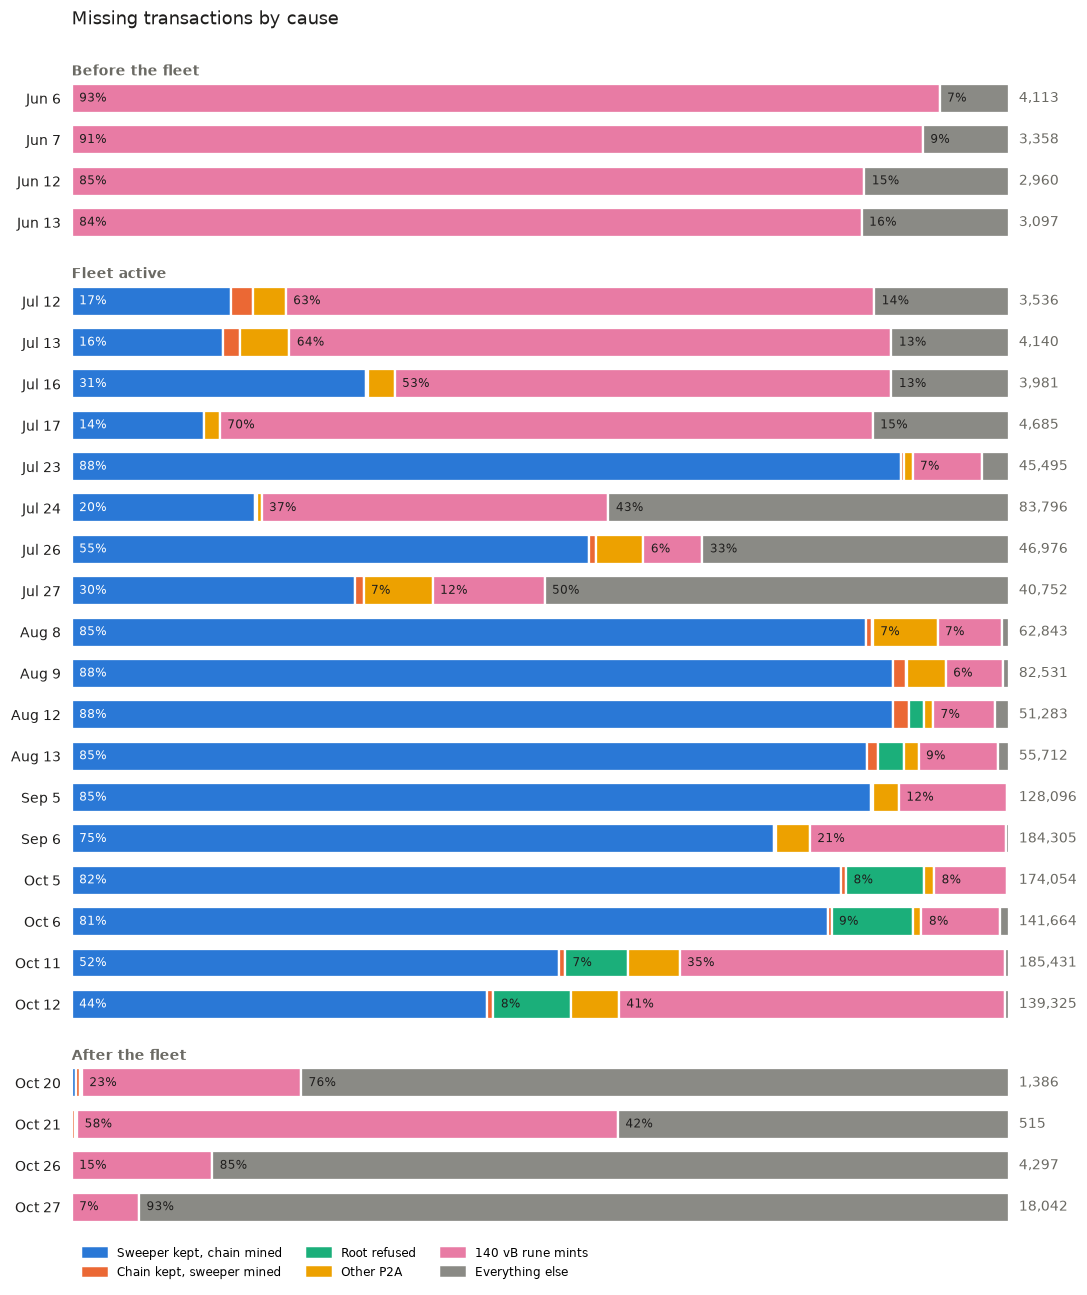

In [5]:
CAUSE_SERIES = [
    ('p2a_sweeper_won_here', 'Sweeper kept, chain mined', BLUE),
    ('p2a_chain_won_here', 'Chain kept, sweeper mined', ORANGE),
    ('p2a_root_conflict', 'Root refused', AQUA),
    ('p2a_other', 'Other P2A', YELLOW),
    ('rune140', '140 vB rune mints', MAGENTA),
    ('other', 'Everything else', GRAY),
]
stack_rows(causes.pivot_table(index='day', columns='cause', values='txs', aggfunc='sum').reindex(columns=CAUSES, fill_value=0),
           CAUSE_SERIES, 'Missing transactions by cause')

## 5. First missing tx of each P2A chain

For the first missing tx of each P2A chain: what it was refused against when it reached us. A sweeper pays the
whole anchor as fee, which is what the rejection line shows. The number of chains is on the right.

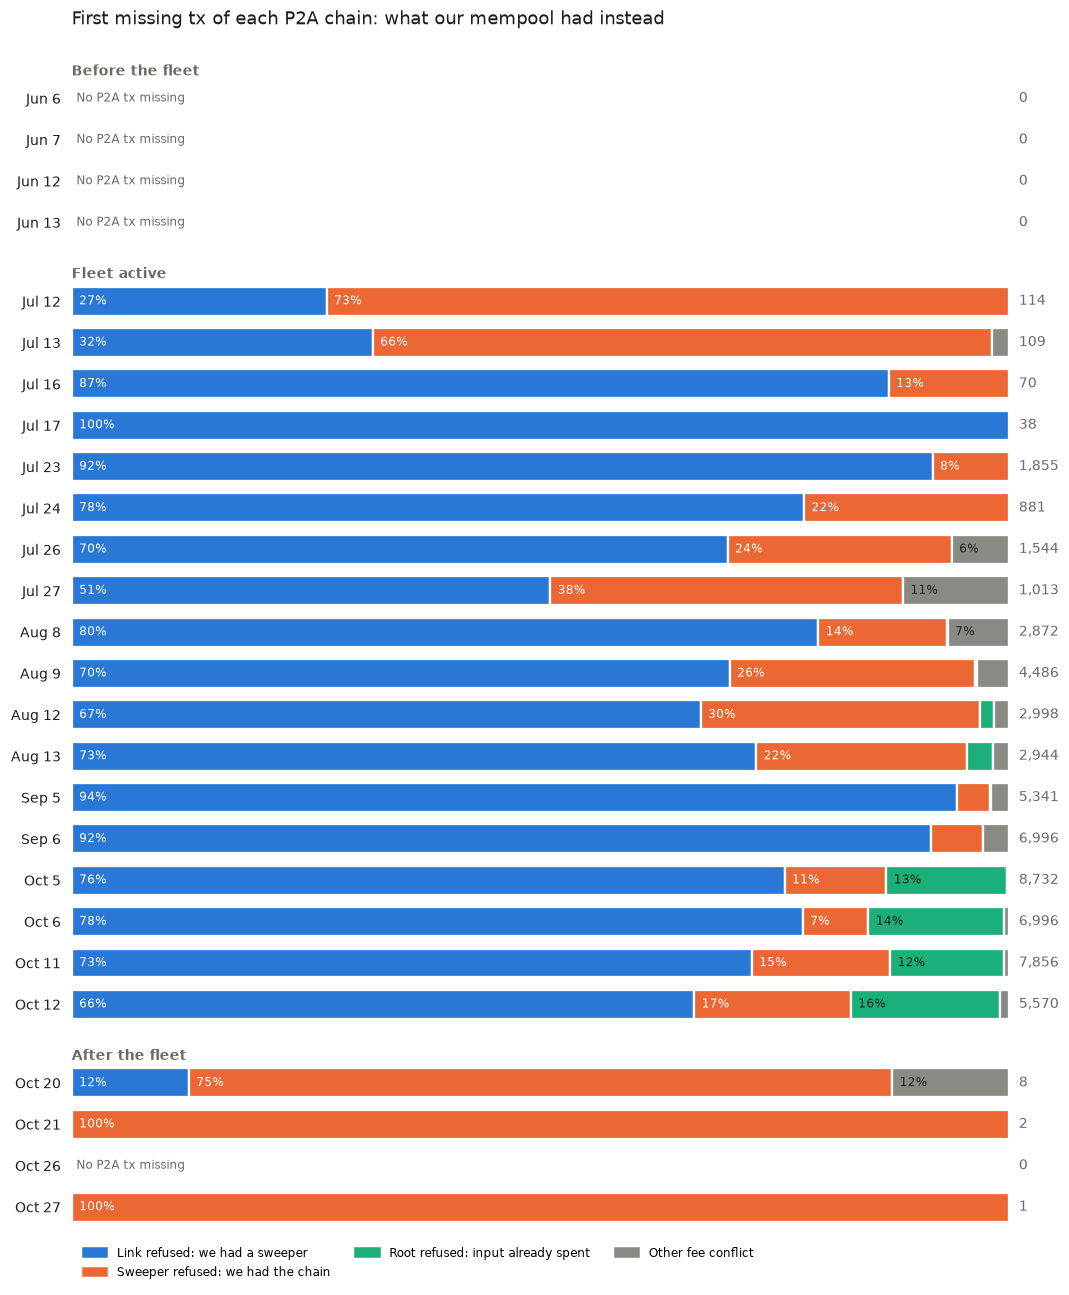

In [6]:
def head_kind(row):
    if 'sweeper' in row.our_mempool_had:
        return 'swept'
    return {'sweeper': 'chain', 'root': 'root'}.get(row.head_role, 'other')


HEAD_SERIES = [
    ('swept', 'Link refused: we had a sweeper', BLUE),
    ('chain', 'Sweeper refused: we had the chain', ORANGE),
    ('root', 'Root refused: input already spent', AQUA),
    ('other', 'Other fee conflict', GRAY),
]
head_counts = (heads.assign(kind=heads.apply(head_kind, axis=1))
               .pivot_table(index='day', columns='kind', values='heads', aggfunc='sum')
               .reindex(index=days, columns=[k for k, _, _ in HEAD_SERIES], fill_value=0).fillna(0))
stack_rows(head_counts, HEAD_SERIES, 'First missing tx of each P2A chain: what our mempool had instead',
           empty='No P2A tx missing')

## 6. Block transactions by kind

Every non-coinbase tx of the day's reconstructed blocks: P2A chain txs (any tx creating or spending a P2A
output), 140 vB rune mints, and everything else.

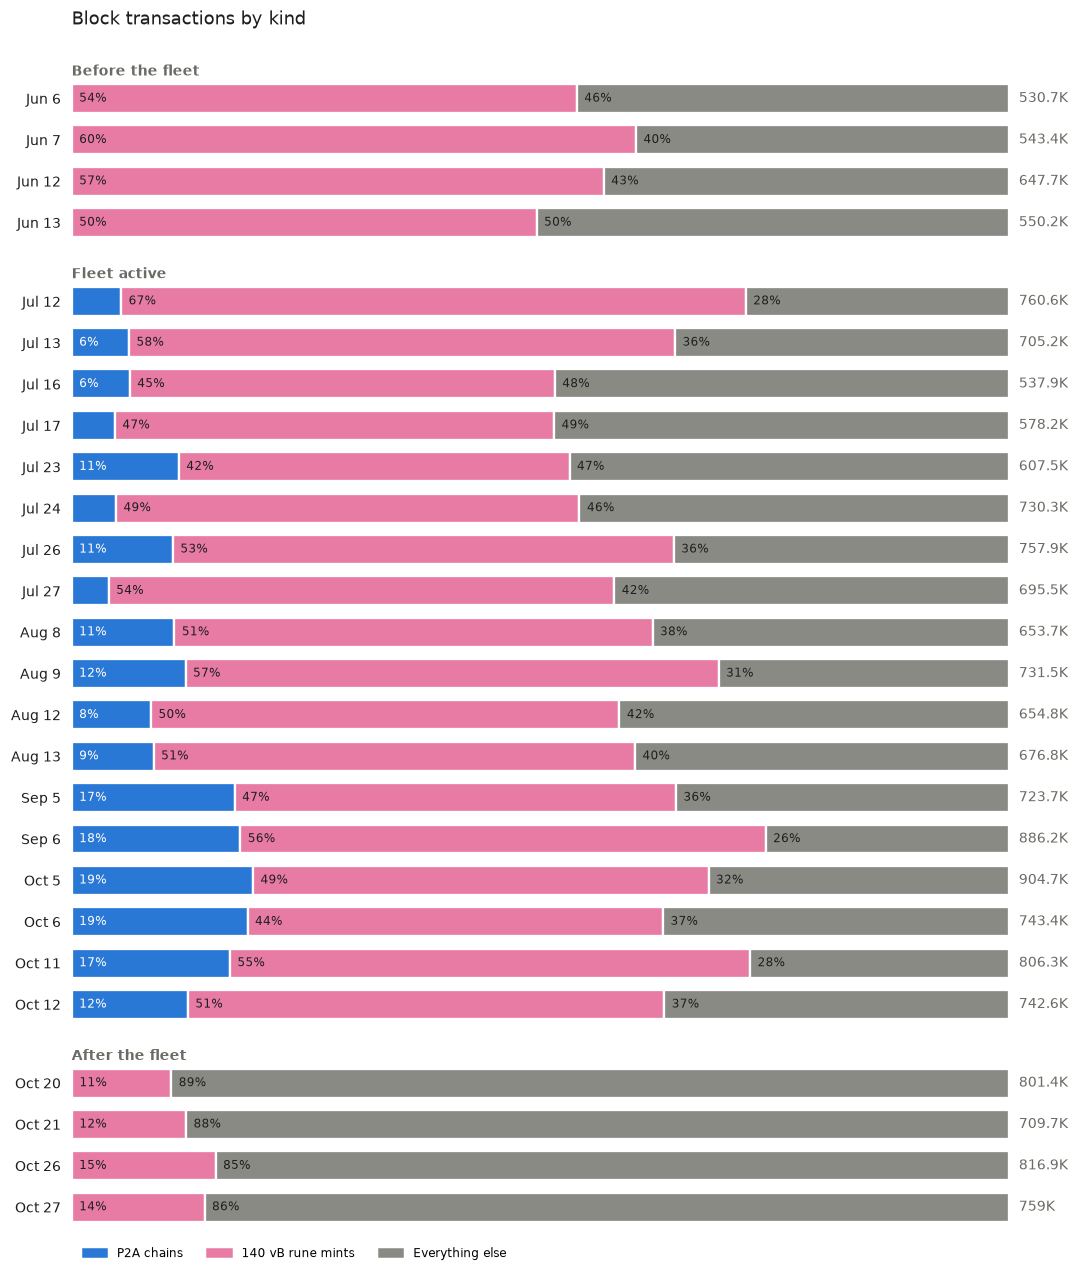

In [7]:
KIND_SERIES = [('p2a', 'P2A chains', BLUE), ('rune140', '140 vB rune mints', MAGENTA), ('other', 'Everything else', GRAY)]
stack_rows(kinds.pivot_table(index='day', columns='type', values='txs', aggfunc='sum')
           .reindex(columns=[k for k, _, _ in KIND_SERIES], fill_value=0),
           KIND_SERIES, 'Block transactions by kind', total_fmt=compact)

## 7. Time to rebuild each block

From the first `Saw new header` of the block to "Successfully reconstructed", per block, log scale. Split by the
BIP152 mode of the peer that first told us of the block: high-bandwidth when it came in a cmpctblock, which only
such a peer sends unasked; low-bandwidth when it came in a headers message, after which the node still has to ask
for the cmpctblock. Black tick: the day's median.

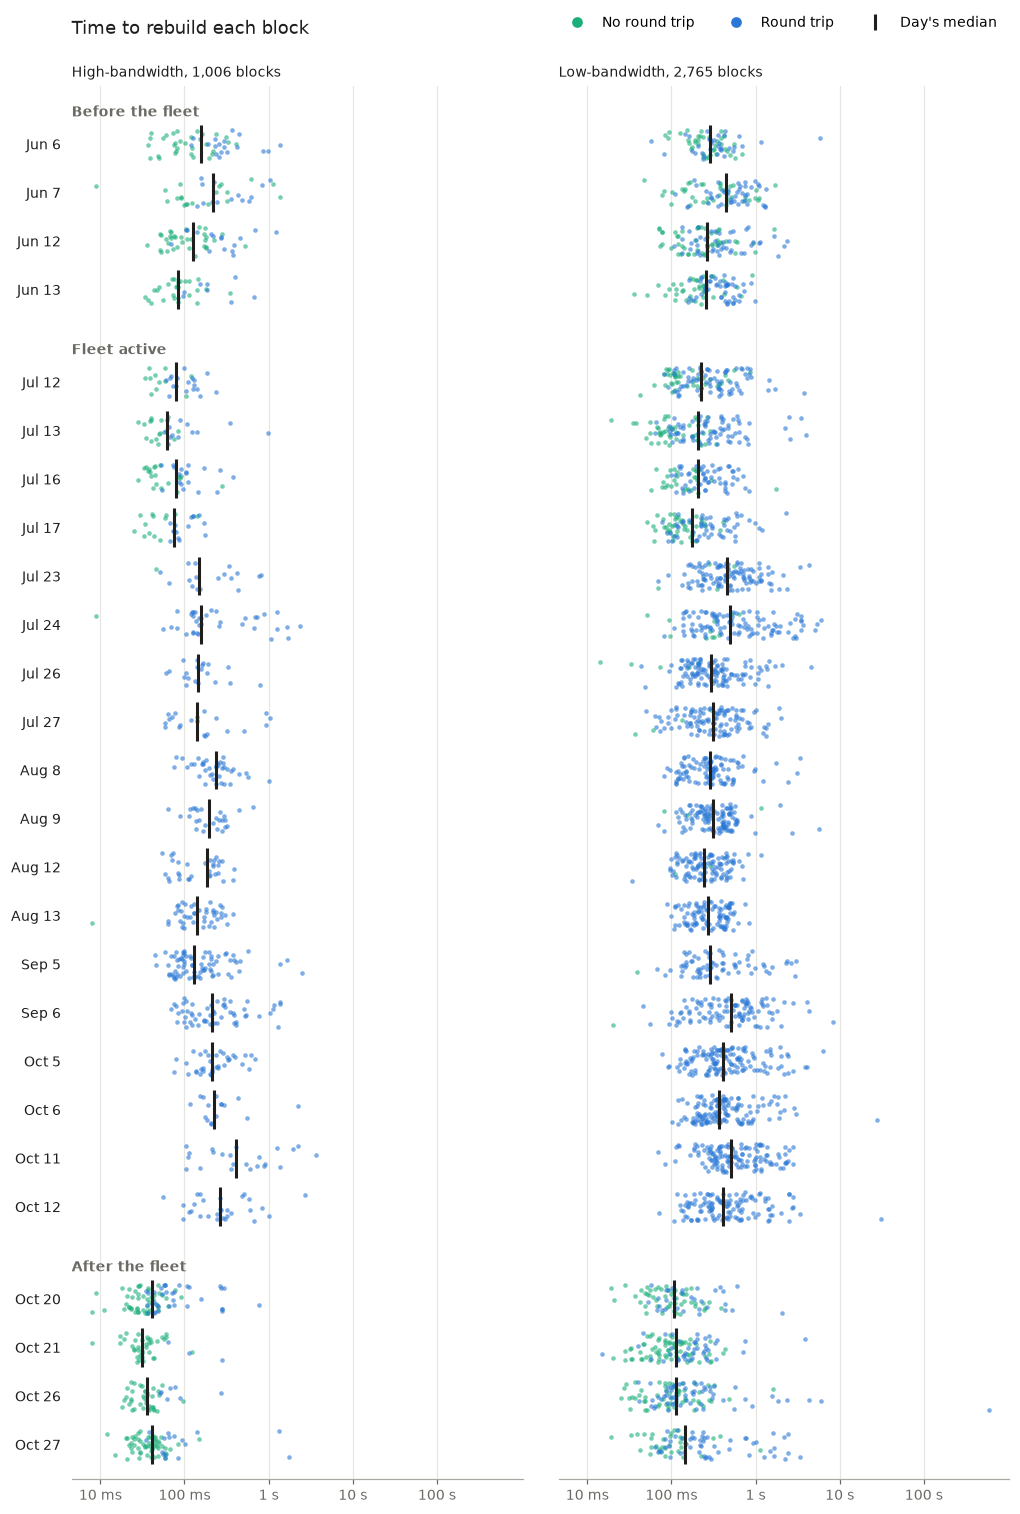

In [8]:
VIA = [('cmpctblock', 'High-bandwidth'), ('headers', 'Low-bandwidth')]
lat = blocks.dropna(subset=['reconstruct_ms']).assign(ms=lambda d: d.reconstruct_ms.clip(lower=1))
height = 0.5 * len(days) + 1.9
fig, axes = plt.subplots(1, 2, figsize=(11, height), sharex=True, sharey=True)
rows = day_axis(axes[0], days)
rng = np.random.default_rng(1)
for ax, (via, title) in zip(axes, VIA):
    for day in days:
        d = lat[(lat.day == day) & (lat.header_via == via)]
        jitter = rows[day] + rng.uniform(-0.3, 0.3, len(d))
        for round_trip, color in ((False, AQUA), (True, BLUE)):
            sel = (d.requested > 0) == round_trip
            ax.scatter(d.ms[sel], jitter[sel.to_numpy()], s=9, color=color, alpha=0.6, lw=0)
        if len(d):
            ax.vlines(d.ms.median(), rows[day] - 0.4, rows[day] + 0.4, color=INK, lw=2)
    ax.set_title(f'{title}, {(lat.header_via == via).sum():,} blocks', color=INK)
    ax.grid(axis='x', color=GRID, lw=0.8)
    ax.set_axisbelow(True)
ax.set_xscale('log')
ticks = [t for t in (1, 10, 100, 1e3, 1e4, 1e5, 1e6) if lat.ms.min() / 3 <= t <= lat.ms.max() * 1.5]
ax.set_xticks(ticks, [f'{t / 1000:g} s' if t >= 1000 else f'{t:g} ms' for t in ticks])
ax.minorticks_off()
fig.subplots_adjust(top=1 - 0.6 / height, wspace=0.08)
fig.legend(handles=[plt.Line2D([], [], ls='', marker='o', color=c) for c in (AQUA, BLUE)]
           + [plt.Line2D([], [], ls='', marker='|', markersize=10, mew=2, color=INK)],
           labels=['No round trip', 'Round trip', "Day's median"], loc='upper right', bbox_to_anchor=(0.9, 1.01),
           ncol=3, frameon=False)
fig.suptitle('Time to rebuild each block', x=0.125, y=1.0, ha='left', fontsize=12, color=INK)
plt.show()